# Chi-Square Goodness-of-Fit Test
---

## Experiment: chi-square test for a six-sided die.

In [1]:
import numpy as np
from scipy.stats import chisquare, chi2

observed = np.array([15, 6, 13, 9, 7, 10])
n = observed.sum()
expected = np.full(6, n / 6)

statistic = np.sum((observed - expected) ** 2 / expected)
df = len(observed) - 1
p_value = chi2.sf(statistic, df)

result = chisquare(f_obs=observed, f_exp=expected)

print(f"Pearson statistic: {statistic:.4f}")
print(f"Degrees of freedom: {df}")
print(f"Manual p-value: {p_value:.6f}")
print(f"SciPy p-value: {result.pvalue:.6f}")

# Experiment: repeat using counts [25, 5, 5, 5, 10, 10].
# How does the evidence against a fair die change?

Pearson statistic: 6.0000
Degrees of freedom: 5
Manual p-value: 0.306219
SciPy p-value: 0.306219


## Experiment: observed counts and Pearson residuals.

Face 1: residual=+1.581, chi-square contribution=2.500
Face 2: residual=-1.265, chi-square contribution=1.600
Face 3: residual=+0.949, chi-square contribution=0.900
Face 4: residual=-0.316, chi-square contribution=0.100
Face 5: residual=-0.949, chi-square contribution=0.900
Face 6: residual=+0.000, chi-square contribution=0.000


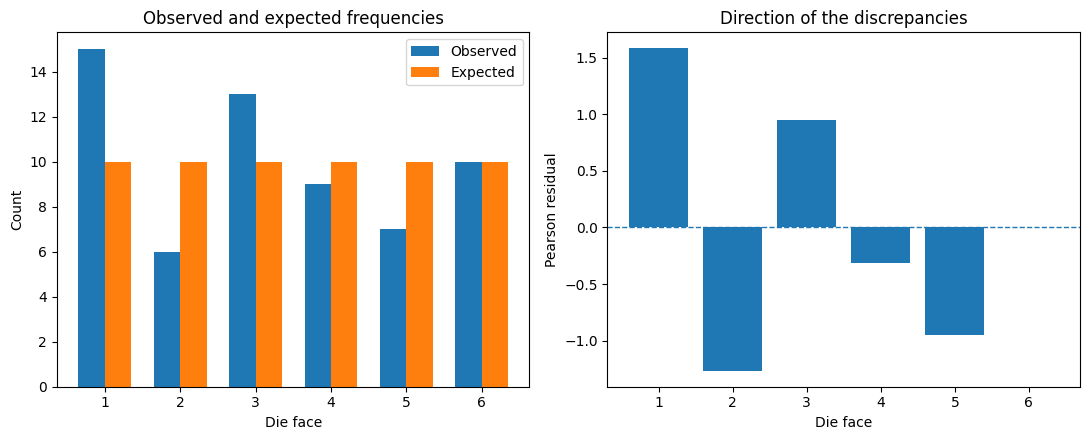

In [1]:
import numpy as np
import matplotlib.pyplot as plt

categories = np.arange(1, 7)
observed = np.array([15, 6, 13, 9, 7, 10])
expected = np.full(6, observed.sum() / 6)

residuals = (observed - expected) / np.sqrt(expected)
contributions = residuals ** 2

for face, residual, contribution in zip(
    categories, residuals, contributions
):
    print(
        f"Face {face}: residual={residual:+.3f}, "
        f"chi-square contribution={contribution:.3f}"
    )

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
width = 0.35

axes[0].bar(categories - width / 2, observed, width, label="Observed")
axes[0].bar(categories + width / 2, expected, width, label="Expected")
axes[0].set_xticks(categories)
axes[0].set_xlabel("Die face")
axes[0].set_ylabel("Count")
axes[0].set_title("Observed and expected frequencies")
axes[0].legend()

axes[1].bar(categories, residuals)
axes[1].axhline(0, linestyle="--", linewidth=1)
axes[1].set_xticks(categories)
axes[1].set_xlabel("Die face")
axes[1].set_ylabel("Pearson residual")
axes[1].set_title("Direction of the discrepancies")

fig.tight_layout()
fig.savefig("../../images/gof_counts_residuals.png", dpi=180, bbox_inches="tight")
plt.show()

# Experiment: compare results for another set of observed counts.

## Experiment: chi-square goodness-of-fit for categorical data.

In [3]:
import numpy as np
import pandas as pd
from scipy.stats import chisquare

categories = ["Catholic", "Muslim", "Orthodox", "Other", "Protestant"]

probabilities = np.array([0.48, 0.02, 0.08, 0.30, 0.12])
observed = np.array([80, 12, 21, 104, 39])

n = observed.sum()
expected = n * probabilities

# Contribution of each category to the chi-square statistic.
contributions = (observed - expected)**2 / expected

summary = pd.DataFrame({
    "category": categories,
    "observed": observed,
    "expected": expected,
    "contribution": contributions
})

# Calculate the test statistic and p-value.
result = chisquare(observed, expected)

print(summary.to_string(index=False))
print(f"\nChi-square statistic: {result.statistic:.6f}")
print(f"Approximate p-value: {result.pvalue:.10g}")
print(f"Degrees of freedom: {len(categories) - 1}")

  category  observed  expected  contribution
  Catholic        80    122.88     14.963333
    Muslim        12      5.12      9.245000
  Orthodox        21     20.48      0.013203
     Other       104     76.80      9.633333
Protestant        39     30.72      2.231719

Chi-square statistic: 36.086589
Approximate p-value: 2.777403263e-07
Degrees of freedom: 4


## Experiment: sampling distribution under the null.

Expected counts: [120.  90.  60.  30.]
Theoretical mean of chi-square: 3
Simulated mean of statistic: 2.981
Nominal Type I error rate: 0.050
Simulated rejection rate: 0.050


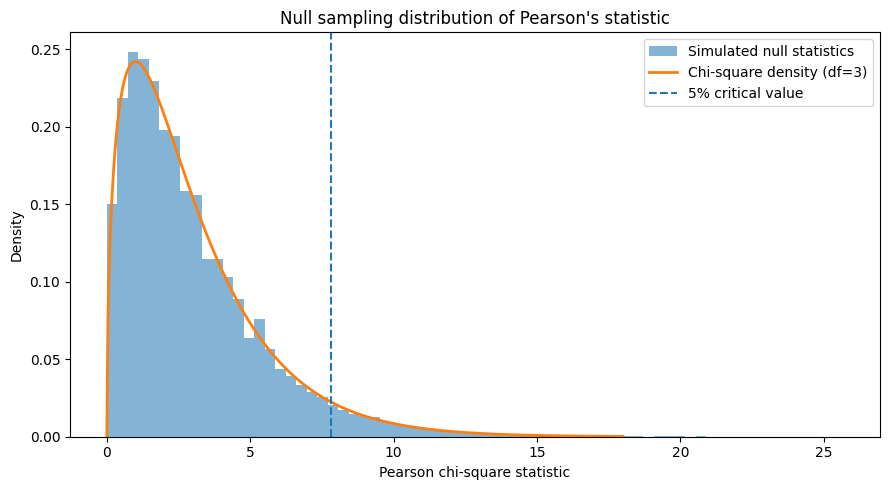

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2

rng = np.random.default_rng(2026)
probabilities = np.array([0.40, 0.30, 0.20, 0.10])
n = 300
repetitions = 30_000

expected = n * probabilities
counts = rng.multinomial(n, probabilities, size=repetitions)
statistics = ((counts - expected) ** 2 / expected).sum(axis=1)

df = len(probabilities) - 1
alpha = 0.05
critical = chi2.isf(alpha, df)

print(f"Expected counts: {expected}")
print(f"Theoretical mean of chi-square: {df}")
print(f"Simulated mean of statistic: {statistics.mean():.3f}")
print(f"Nominal Type I error rate: {alpha:.3f}")
print(f"Simulated rejection rate: {np.mean(statistics > critical):.3f}")

x = np.linspace(0, 18, 500)
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(statistics, bins=70, density=True, alpha=0.55,
        label="Simulated null statistics")
ax.plot(x, chi2.pdf(x, df), linewidth=2,
        label=f"Chi-square density (df={df})")
ax.axvline(critical, linestyle="--", label="5% critical value")
ax.set_xlabel("Pearson chi-square statistic")
ax.set_ylabel("Density")
ax.set_title("Null sampling distribution of Pearson's statistic")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/gof_chi_square_null.png", dpi=180, bbox_inches="tight")
plt.show()

# Experiment: reduce n from 300 to 30.
# How well does the chi-square approximation work?

## Experiment: sparse expected counts and Monte Carlo testing.

In [5]:
import numpy as np
from scipy.stats import chi2

rng = np.random.default_rng(2026)
probabilities = np.array([0.80, 0.15, 0.04, 0.01])
observed = np.array([28, 9, 3, 0])

n = observed.sum()
expected = n * probabilities
observed_q = ((observed - expected) ** 2 / expected).sum()

asymptotic_p = chi2.sf(observed_q, df=len(probabilities) - 1)

B = 100_000
null_counts = rng.multinomial(n, probabilities, size=B)
null_q = ((null_counts - expected) ** 2 / expected).sum(axis=1)
monte_carlo_p = (1 + np.count_nonzero(null_q >= observed_q)) / (B + 1)

print("Expected counts:", expected)
print(f"Observed statistic: {observed_q:.4f}")
print(f"Chi-square approximate p-value: {asymptotic_p:.5f}")
print(f"Monte Carlo p-value: {monte_carlo_p:.5f}")

# Examine Type I error for an asymptotic 5% test.
critical = chi2.isf(0.05, df=len(probabilities) - 1)
print(
    "Simulated rejection rate using chi-square cutoff:",
    f"{np.mean(null_q > critical):.3f}"
)

# Experiment: increase n so that every expected count is at least 5.

Expected counts: [32.   6.   1.6  0.4]
Observed statistic: 3.6250
Chi-square approximate p-value: 0.30491
Monte Carlo p-value: 0.25201
Simulated rejection rate using chi-square cutoff: 0.068


## Experiment: fitted probabilities and degrees of freedom.

In [6]:
import numpy as np
from scipy.stats import chisquare, chi2

# Illustrative genotype counts, not a real population survey.
observed = np.array([56, 26, 18])  # AA, Aa, aa
n = observed.sum()

theta_hat = (2 * observed[0] + observed[1]) / (2 * n)
expected_probabilities = np.array([
    theta_hat ** 2,
    2 * theta_hat * (1 - theta_hat),
    (1 - theta_hat) ** 2
])
expected = n * expected_probabilities

# One free parameter is fitted from the same category counts.
df = len(observed) - 1 - 1
statistic = ((observed - expected) ** 2 / expected).sum()
p_value = chi2.sf(statistic, df)

# SciPy's ddof accounts for the fitted parameter here.
result = chisquare(observed, expected, ddof=1)

print(f"Estimated allele frequency: {theta_hat:.4f}")
print("Expected counts:", np.round(expected, 3))
print(f"Degrees of freedom: {df}")
print(f"Chi-square statistic: {statistic:.4f}")
print(f"Approximate p-value: {p_value:.6f}")
print(result.pvalue)

# Experiment: compare with the incorrect choice df=2.

Estimated allele frequency: 0.6900
Expected counts: [47.61 42.78  9.61]
Degrees of freedom: 1
Chi-square statistic: 15.3852
Approximate p-value: 0.000088
8.767359885367621e-05


## Experiment: simulated power and sample size.

n=  50 | Type I rate=0.047 | power=0.087
n= 100 | Type I rate=0.051 | power=0.149
n= 200 | Type I rate=0.049 | power=0.264
n= 400 | Type I rate=0.046 | power=0.500
n= 800 | Type I rate=0.048 | power=0.836
Specified alternative effect size w = 0.1208


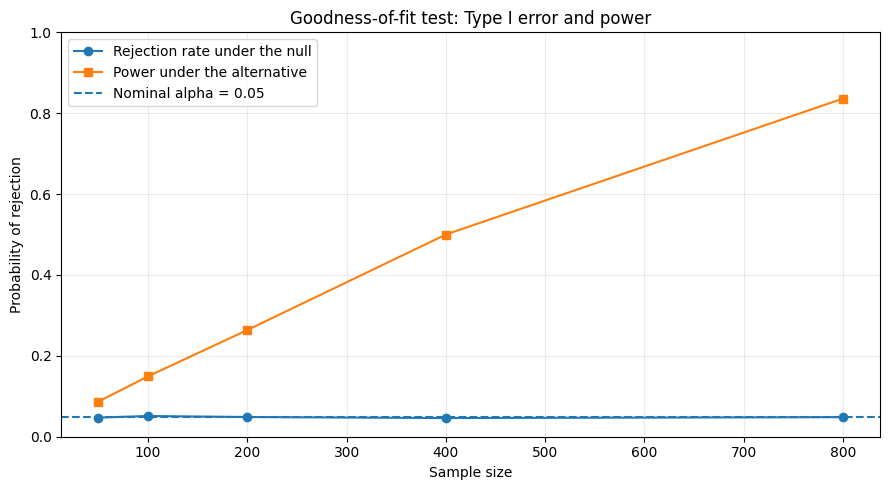

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2

rng = np.random.default_rng(2026)
p_null = np.array([0.40, 0.30, 0.20, 0.10])
p_alternative = np.array([0.45, 0.25, 0.20, 0.10])

sample_sizes = [50, 100, 200, 400, 800]
repetitions = 10_000
alpha = 0.05

df = len(p_null) - 1
critical = chi2.isf(alpha, df)
w = np.sqrt(np.sum((p_alternative - p_null) ** 2 / p_null))

false_positive_rates = []
powers = []

for n in sample_sizes:
    expected = n * p_null
    under_null = rng.multinomial(n, p_null, size=repetitions)
    under_alt = rng.multinomial(n, p_alternative, size=repetitions)

    q_null = ((under_null - expected) ** 2 / expected).sum(axis=1)
    q_alt = ((under_alt - expected) ** 2 / expected).sum(axis=1)

    false_positive_rates.append(np.mean(q_null > critical))
    powers.append(np.mean(q_alt > critical))

    print(
        f"n={n:4d} | Type I rate={false_positive_rates[-1]:.3f} "
        f"| power={powers[-1]:.3f}"
    )

print(f"Specified alternative effect size w = {w:.4f}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(sample_sizes, false_positive_rates, marker="o",
        label="Rejection rate under the null")
ax.plot(sample_sizes, powers, marker="s",
        label="Power under the alternative")
ax.axhline(alpha, linestyle="--", label="Nominal alpha = 0.05")
ax.set_xlabel("Sample size")
ax.set_ylabel("Probability of rejection")
ax.set_ylim(0, 1)
ax.set_title("Goodness-of-fit test: Type I error and power")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig("../../images/gof_power_sample_size.png", dpi=180, bbox_inches="tight")
plt.show()

# Experiment: make the alternative probabilities closer to p_null.
# How does the power curve change?